# Experiment 2: Logistic Regression
**Case Study:** Predict Student Pass/Fail based on Study Hours and Attendance (12-row assumed dataset)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

### Deliverable 1 & 2: Plot Sigmoid Function

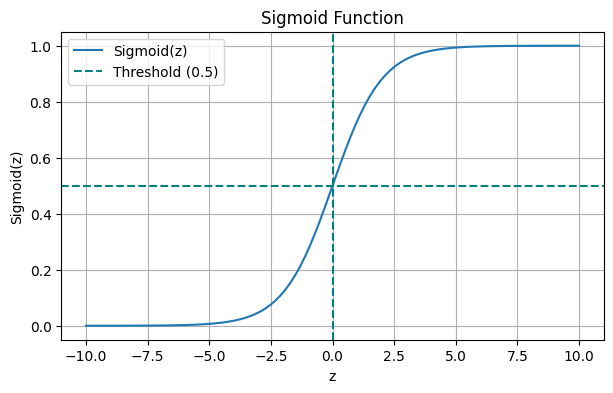

In [2]:
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid, label='Sigmoid(z)')
plt.axhline(0.5, color='teal', linestyle='--', label='Threshold (0.5)')
plt.axvline(0.0, color='teal', linestyle='--')
plt.title('Sigmoid Function')
plt.xlabel('z')
plt.ylabel('Sigmoid(z)')
plt.grid(True)
plt.legend()
plt.show()

### Deliverable 3: Create Assumed Dataset (12 Rows) & Apply LogisticRegression()

In [3]:
# Assumed Dataset: Predict if a student passes (1) or fails (0)
data = {
    'Study_Hours': [1, 2, 2.5, 3, 3.5, 4, 5, 6, 6.5, 7, 8, 9],
    'Attendance_Pct': [40, 45, 50, 55, 60, 62, 70, 75, 80, 85, 88, 92],
    'Pass': [0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)
print("--- Assumed Dataset ---")
print(df.to_string(index=False))

X = df[['Study_Hours', 'Attendance_Pct']]
y = df['Pass']

# Train-Test Split (70% train, 30% test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression Model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print('\nTraining samples:', len(X_train))
print('Testing samples :', len(X_test))
print('Actual classes  :', y_test.values)
print('Predicted classes:', y_pred)

--- Assumed Dataset ---
 Study_Hours  Attendance_Pct  Pass
         1.0              40     0
         2.0              45     0
         2.5              50     0
         3.0              55     0
         3.5              60     0
         4.0              62     0
         5.0              70     1
         6.0              75     1
         6.5              80     1
         7.0              85     1
         8.0              88     1
         9.0              92     1

Training samples: 8
Testing samples : 4
Actual classes  : [1 1 0 0]
Predicted classes: [1 1 0 0]


### Deliverable 4 & 5: Accuracy Measures, Confusion Matrix & ROC Curve

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000
ROC-AUC  : 1.0000

Classification Report:
              precision    recall  f1-score   support

    Fail (0)       1.00      1.00      1.00         2
    Pass (1)       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

Confusion Matrix:
 [[2 0]
 [0 2]]


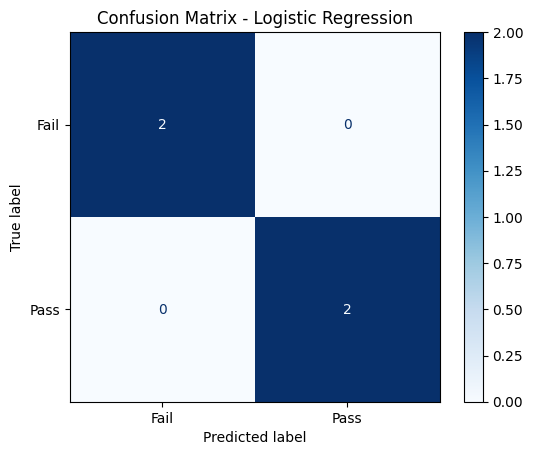

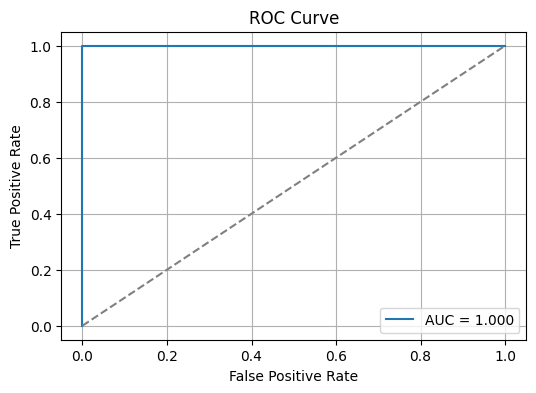

In [4]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Fail (0)', 'Pass (1)'], zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

ConfusionMatrixDisplay(cm, display_labels=['Fail', 'Pass']).plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()